In [3]:
import wandb
import pandas as pd
api = wandb.Api()

In [23]:
import numpy as np
from matplotlib import pyplot as plt

def _plot_group_diff(ax, df, groups, tasks, baseline_group, title, ci_z=1.96):
    """Plots relative-diff bars for one job_type panel onto a given axis,
    plus a shaded 95% CI band (relative to baseline) per task."""
    if not tasks:
        ax.set_title(f"{title} (sin datos)")
        ax.axis("off")
        return

    mean_scores = {}
    for group in groups:
        for t in tasks:
            subset = df[(df["group"] == group) & (df["task_label"] == t)]
            metric = subset["best_score"]
            mean_scores[(group, t)] = metric.mean() if len(metric) else np.nan

    baseline_means = np.array([mean_scores[(baseline_group, t)] for t in tasks])
    plot_groups = [g for g in groups if g != baseline_group]
    n_groups = len(plot_groups)

    x = np.arange(len(tasks))
    width = 0.8 / max(n_groups, 1)

    for i, group in enumerate(plot_groups):
        group_means = np.array([mean_scores[(group, t)] for t in tasks])

        with np.errstate(invalid="ignore", divide="ignore"):
            rel_diff = (group_means - baseline_means) / baseline_means

        missing = np.isnan(group_means) | np.isnan(baseline_means) | (baseline_means == 0)
        vals = np.where(missing, 0.0, rel_diff)

        # correct centering: offsets span -(n-1)/2*width .. +(n-1)/2*width around x
        offset = (i - (n_groups - 1) / 2) * width
        bars = ax.bar(x + offset, vals, width, label=group)
        labels = ["skip" if m else f"{b.get_height():+.1%}" for b, m in zip(bars, missing)]
        ax.bar_label(bars, labels=labels, padding=3, fontsize=7, rotation=90)

    # --- 95% CI band for the baseline, per task, expressed in relative-diff units ---
    cluster_half_width = 0.8 / 2
    ci_label_used = False
    for j, t in enumerate(tasks):
        baseline_runs = df[(df["group"] == baseline_group) & (df["task_label"] == t)]["best_score"].dropna()
        n = len(baseline_runs)
        b_mean = baseline_runs.mean() if n else np.nan

        if n < 2 or not np.isfinite(b_mean) or b_mean == 0:
            continue

        sem = baseline_runs.std(ddof=1) / np.sqrt(n)
        margin = ci_z * sem / abs(b_mean)

        ax.fill_between(
            [x[j] - cluster_half_width, x[j] + cluster_half_width],
            -margin, margin,
            color="gray", alpha=0.2, edgecolor=None, zorder=9,
            label="95% CI (baseline)" if not ci_label_used else None,
        )
        ci_label_used = True

    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_xticks(x)
    ax.set_xticklabels(tasks, rotation=45, ha="right")
    if title == "chromatin_profile_prediction":
        ax.get_xaxis().set_visible(False)
    
    ax.set_ylabel(f"Dif. relativa vs '{baseline_group}'")

    mapper = {
        "nt_benchmark": "NT Benchmark",
        "genomic_benchmark": "Genomic Benchmark",
        "bend_benchmark": "BEND Benchmark",
        "chromatin_profile_prediction": "Chromatin Profile Prediction"
    }
    
    ax.set_title(mapper[title])
    ax.margins(y=0.25)

def runs_on_task_bar_chart(
    runs_dict,
    baseline_group=None,
    row1_job_type="nt_benchmark",
    row2_job_types=("genomic_benchmark", "bend_benchmark", "chromatin_profile_prediction"),
    row2_width_ratios=None,
    min_width_ratio=2,
    row_height=6,
    width_per_task=0.9,
    save_name = None
):
    df_list = []
    for group_name, runs in runs_dict.items():
        for run in runs:
            df_list.append(
                run.summary._json_dict | {
                    "name": run.name,
                    "id": run.id,
                    "tags": run.tags,
                    "group": group_name,
                    "job_type": run.job_type,
                    "downstream_task": run.config.get("dataset", {}).get("dataset_name"),
                    "orients_promoters": run.config.get("canonicalization", {}).get("orient_promoters", False),
                }
            )

    df = pd.DataFrame(df_list)
    df["task_label"] = df["downstream_task"].fillna(df["job_type"])

    groups = sorted(df["group"].dropna().unique())
    if baseline_group is None:
        baseline_group = groups[0]
    if baseline_group not in groups:
        raise ValueError(f"baseline_group '{baseline_group}' not found in groups {groups}")

    def tasks_for(job_type):
        return sorted(df.loc[df["job_type"] == job_type, "task_label"].dropna().unique())

    row1_tasks = tasks_for(row1_job_type)
    row2_tasks = [tasks_for(jt) for jt in row2_job_types]

    if row2_width_ratios is None:
        ratios = [max(len(tasks), min_width_ratio) for tasks in row2_tasks]
    else:
        ratios = list(row2_width_ratios)

    n_cols = len(row2_job_types)
    total_width = max(width_per_task * sum(ratios), width_per_task * min_width_ratio)
    fig = plt.figure(figsize=(total_width, row_height * 2))
    gs = fig.add_gridspec(2, n_cols, width_ratios=ratios, height_ratios=[1, 1])

    ax_row1 = fig.add_subplot(gs[0, :])
    panel_df = df[df["job_type"] == row1_job_type]
    _plot_group_diff(ax_row1, panel_df, groups, row1_tasks, baseline_group, title=row1_job_type)

    row2_axes = []
    for col, (jt, tasks) in enumerate(zip(row2_job_types, row2_tasks)):
        ax = fig.add_subplot(gs[1, col])
        panel_df = df[df["job_type"] == jt]
        _plot_group_diff(ax, panel_df, groups, tasks, baseline_group, title=jt)
        row2_axes.append(ax)

    # single figure-level legend, built from whichever axis actually has
    # plotted handles (colors/order are consistent across panels since
    # plot_groups = groups minus baseline, same set everywhere)
    handles, labels = [], []
    for ax in [ax_row1, *row2_axes]:
        h, l = ax.get_legend_handles_labels()
        if h:
            handles, labels = h, l
            break

    if handles:
        fig.legend(handles, labels, loc="upper center", ncol=len(labels),
                    bbox_to_anchor=(0.5, 1.02), fontsize=9)

    fig.suptitle("Differences relative to baseline for canonicalized and leakage control models", fontsize=14, y=1.06)
    plt.tight_layout()
    if save_name is not None:
        plt.savefig(save_name, dpi=300, bbox_inches="tight")
    plt.show()

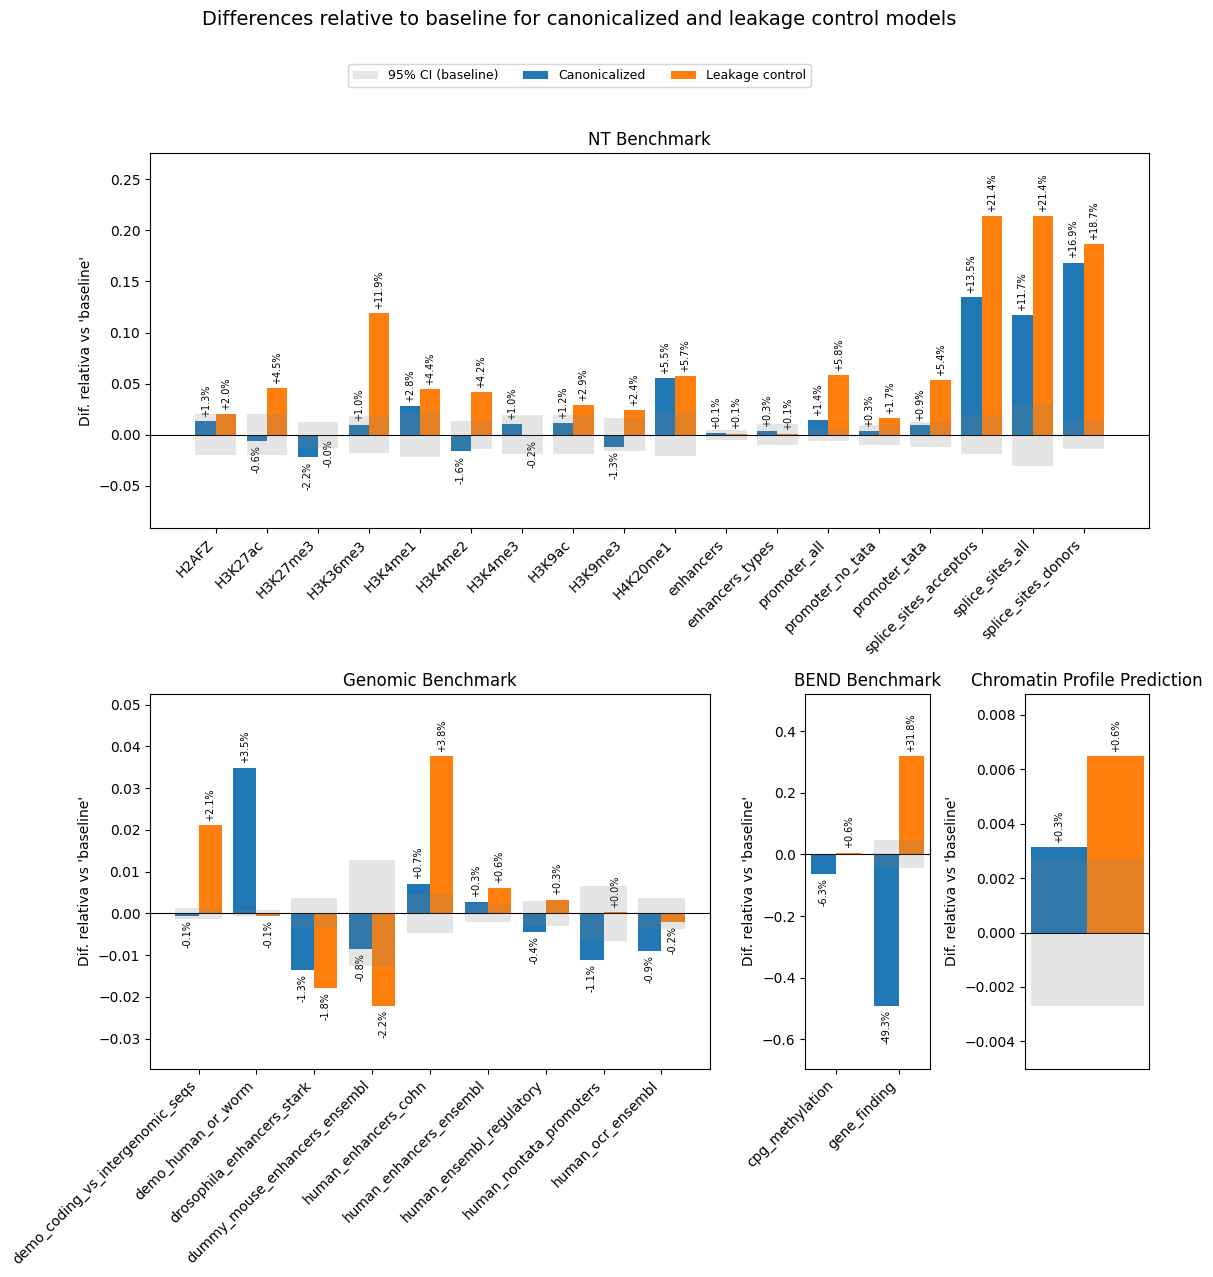

In [24]:
raw_control_signal = api.runs("pipe-verri-gh/Canonicalization", filters={
    "group": "raw_control_signal"
})
canonicalized = api.runs("pipe-verri-gh/Canonicalization", filters={
    "group": "canonicalized"
})
baseline = api.runs("pipe-verri-gh/Canonicalization", filters={
    "group": "baseline"
})

runs_on_task_bar_chart({"Canonicalized": canonicalized, "Leakage control": raw_control_signal, "baseline": baseline}, baseline_group="baseline", save_name="ablation.png")

In [12]:
from scipy import stats

def canon_vs_controls_pvalue_bar_chart(runs_dict, metric="best_score"):
    """
    runs_dict: dict con keys 'baseline', 'canonicalized', 'raw_control_signals',
    cada una con una lista de wandb runs.

    Por cada task calcula:
      - p1 = P(canonicalized > baseline)  (t-test right-tail)
      - p2 = P(canonicalized > raw_control_signals) (t-test right-tail)
    y plotea el max(p1, p2) por task (peor caso de los dos tests).
    """
    df_list = []
    for group_name, runs in runs_dict.items():
        for run in runs:
            df_list.append(
                run.summary._json_dict | {
                    "name": run.name,
                    "id": run.id,
                    "tags": run.tags,
                    "group": group_name,
                    "downstream_task": run.config.get("dataset", {}).get("dataset_name") if run.job_type != "chromatin_profile_prediction" else "chromatin_profile_prediction",
                }
            )

    df = pd.DataFrame(df_list)

    required_groups = {"baseline", "canonicalized", "raw_control_signals"}
    missing_groups = required_groups - set(df["group"].dropna().unique())
    if missing_groups:
        raise ValueError(f"Faltan grupos en runs_dict: {missing_groups}")

    tasks = sorted(df["downstream_task"].dropna().unique())
    if "hg38" in tasks:
        tasks.remove("hg38")

    max_pvals = []
    p_vs_baseline = []
    p_vs_raw = []
    skipped = []

    for t in tasks:
        canon = df[(df["group"] == "canonicalized") & (df["downstream_task"] == t)][metric].dropna()
        base = df[(df["group"] == "baseline") & (df["downstream_task"] == t)][metric].dropna()
        raw = df[(df["group"] == "raw_control_signals") & (df["downstream_task"] == t)][metric].dropna()

        if len(canon) < 2 or len(base) < 2 or len(raw) < 2:
            max_pvals.append(np.nan)
            p_vs_baseline.append(np.nan)
            p_vs_raw.append(np.nan)
            skipped.append(t)
            continue

        p1 = stats.ttest_ind(canon, base, alternative="greater", equal_var=True).pvalue
        p2 = stats.ttest_ind(canon, raw, alternative="greater", equal_var=True).pvalue

        p_vs_baseline.append(p1)
        p_vs_raw.append(p2)
        max_pvals.append(max(p1, p2))

    x = np.arange(len(tasks))
    missing = np.isnan(max_pvals)
    vals = np.nan_to_num(max_pvals, nan=0.0)

    fig, ax = plt.subplots(figsize=(14, 5))
    bars = ax.bar(x, vals, width=0.6, color="steelblue")

    labels = ["skip" if m else f"{v:.3f}" for m, v in zip(missing, vals)]
    ax.bar_label(bars, labels=labels, padding=3)

    ax.axhline(0.05, color="red", linestyle="--", linewidth=1, label="p = 0.05")

    ax.set_xticks(x)
    ax.set_xticklabels(tasks, rotation=45, ha="right")
    ax.set_ylabel("max(p_vs_baseline, p_vs_raw_control)")
    ax.set_title("Peor p-valor (right-tail t-test) de canonicalized superando a baseline / raw_control_signals, por task")
    ax.legend()

    plt.tight_layout()
    plt.show()

    return pd.DataFrame({
        "task": tasks,
        "p_canon_gt_baseline": p_vs_baseline,
        "p_canon_gt_raw_control": p_vs_raw,
        "max_p": max_pvals,
    })

/tmp/ipykernel_150838/2217174659.py:54: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  p1 = stats.ttest_ind(canon, base, alternative="greater", equal_var=True).pvalue
/tmp/ipykernel_150838/2217174659.py:55: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  p2 = stats.ttest_ind(canon, raw, alternative="greater", equal_var=True).pvalue


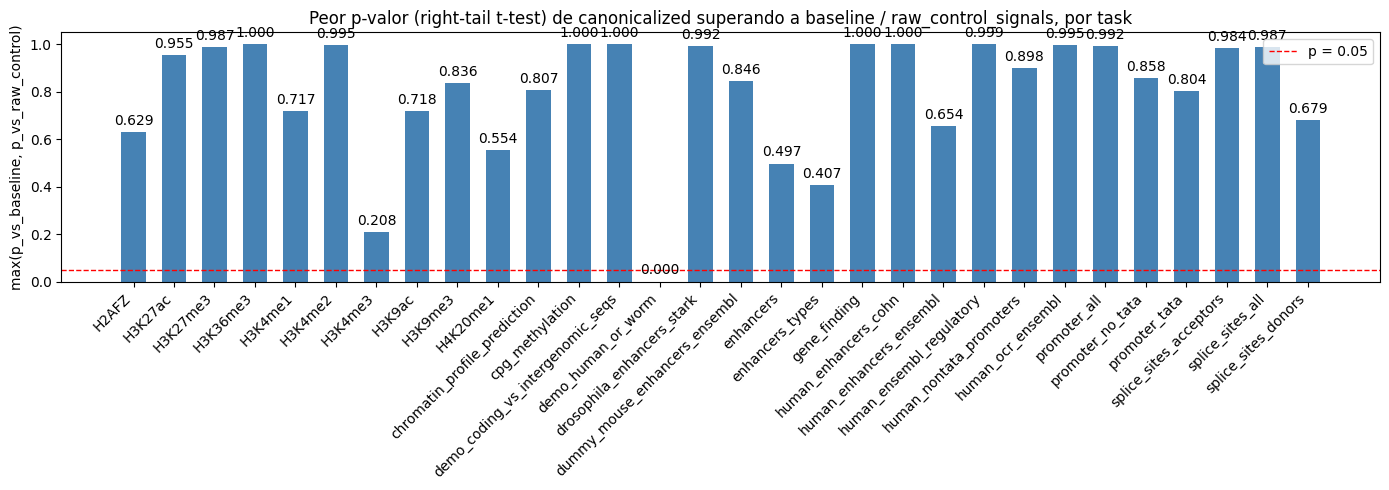

,task,p_canon_gt_baseline,p_canon_gt_raw_control,max_p
0,H2AFZ,2.308281e-01,6.294574e-01,6.294574e-01
1,H3K27ac,6.063024e-01,9.550394e-01,9.550394e-01
2,H3K27me3,9.866961e-01,9.654748e-01,9.866961e-01
3,H3K36me3,1.759298e-01,9.999504e-01,9.999504e-01
4,H3K4me1,4.884868e-02,7.166799e-01,7.166799e-01
5,H3K4me2,8.758079e-01,9.952280e-01,9.952280e-01
6,H3K4me3,2.083643e-01,1.319286e-01,2.083643e-01
7,H3K9ac,3.301061e-01,7.178990e-01,7.178990e-01
8,H3K9me3,7.369405e-01,8.357954e-01,8.357954e-01
9,H4K20me1,2.274988e-03,5.536618e-01,5.536618e-01


In [9]:
canon_vs_controls_pvalue_bar_chart({
    "baseline": baseline,
    "canonicalized": canonicalized,
    "raw_control_signals": raw_control_signal
})